## **CATATAN**

- `produksi_ton`: Total produksi budidaya (ton)
- `rtp`: Jumlah Rumah Tangga Perikanan
- `pembudidaya`: Jumlah orang yang membudidayakan ikan
- `luas_lahan_ha`: Luas lahan budidaya (ha)
- `total_pembesaran`: Total produksi pembesaran (ton)


menjawab pertanyaan "Kabupaten mana yang mirip satu sama lain berdasarkan skala & karakteristik budidaya perikanannya?"

**Gunanya**

- **Segmentasi wilayah**: Pemerintah dapat mengetahui kabupaten mana yang membutuhkan intervensi berbeda.
- **Prioritas kebijakan**: 
  - Klaster "Spesialis Kepulauan" membutuhkan bantuan pengembangan rumput laut.
  - Klaster "Raksasa Budidaya" membutuhkan pengembangan hilirisasi.
  - Klaster "Skala Menengah" membutuhkan pendampingan UMKM.
- **Benchmarking**: Kabupaten dalam klaster yang sama dapat saling belajar dan berbagi *best practice*.
- **Dasar regresi Notebook 4**: Klaster dapat digunakan sebagai fitur tambahan untuk memprediksi produksi.
- **Dasar dashboard**: Menampilkan peta dan warna klaster agar informasi mudah dipahami oleh pemangku kepentingan.

## 3️⃣ Makna 3 Klaster (Karakteristik)

### 🏝️ K0 — Spesialis Kepulauan (Rumput Laut)
**Anggota:** Sumenep.

- **Produksi ikan:** 5.162 ton (rendah).
- **Total pembesaran:** 1.186.176 ton (sangat tinggi).
- **Luas lahan:** 749 ha (relatif kecil).

**Interpretasi:** Sumenep memiliki karakteristik budidaya yang berbeda, terutama pada rumput laut dan hasil laut non-ikan. Prioritas kebijakan adalah hilirisasi dan pengembangan produk rumput laut.

---

### 🏙️ K1 — Skala Menengah (Kabupaten Umum)
**Anggota:** 28 kabupaten, termasuk Bangkalan, Banyuwangi, dan Jember.

- **Produksi:** 13.344 ton.
- **RTP:** 1.875 rumah tangga.
- **Luas lahan:** 3.577 ha.
- **Total pembesaran:** 16.884 ton.

**Interpretasi:** Klaster ini mewakili mayoritas kabupaten dengan skala budidaya menengah. Prioritasnya adalah pendampingan UMKM, perluasan akses pasar, dan peningkatan teknologi budidaya.

---

### 🐟 K2 — Raksasa Budidaya (Tinggi)
**Anggota:** Gresik, Lamongan, Sidoarjo, dan Tulungagung.

- **Produksi:** 76.662 ton (sekitar 5,7 kali K1).
- **RTP:** 18.341 rumah tangga.
- **Pembudidaya:** 19.792 orang.
- **Luas lahan:** 22.252 ha.

**Interpretasi:** Klaster ini memiliki skala budidaya besar. Prioritasnya adalah hilirisasi, penguatan pasar dan ekspor, serta pengelolaan lingkungan yang berkelanjutan.

In [43]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
import joblib

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

ROOT = Path.cwd().parent if (Path.cwd().name == 'notebooks') else Path.cwd()
sys.path.append(str(ROOT / 'src'))
try:
    from config import PROCESSED_DIR, MODEL_DIR, REPORT_DIR, FIG_DIR, SUMBER
except Exception:
    PROCESSED_DIR = ROOT / 'data' / 'processed'
    MODEL_DIR = ROOT / 'output' / 'models'
    REPORT_DIR = ROOT / 'output' / 'reports'
    FIG_DIR = ROOT / 'output' / 'figures'
    for d in [PROCESSED_DIR, MODEL_DIR, REPORT_DIR, FIG_DIR]:
        d.mkdir(parents=True, exist_ok=True)
    SUMBER = {}
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('ROOT:', ROOT)

ROOT: e:\Aulia\kuliah\TUGAS LAPRAK SMT 7\MAGANG\PROJECT\Perikanan


In [44]:
df = pd.read_parquet(PROCESSED_DIR / 'features_model.parquet')
FITUR = ['produksi_ton', 'rtp', 'pembudidaya', 'luas_lahan_ha', 'total_pembesaran']
FITUR = [f for f in FITUR if f in df.columns]

df_model = df.dropna(subset=FITUR).copy()

print(f'Baris awal          : {len(df)}')
print(f'Baris setelah drop  : {len(df_model)}')
print(f'Kabupaten unik      : {df_model.kabupaten.nunique()}')
print(f'Tahun               : {sorted(df_model.tahun.unique().tolist())}')

Baris awal          : 190
Baris setelah drop  : 134
Kabupaten unik      : 31
Tahun               : [2020, 2021, 2022, 2023, 2024]


In [45]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_model[FITUR])

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
var = pca.explained_variance_ratio_ * 100

print(f'PC1: {var[0]:.2f}% | PC2: {var[1]:.2f}% | Total: {var.sum():.2f}%')

PC1: 51.60% | PC2: 20.42% | Total: 72.02%


In [46]:
hasil = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_pca)
    hasil.append({
        'k': k,
        'inertia': km.inertia_,
        'silhouette': silhouette_score(X_pca, labels),
        'davies_bouldin': davies_bouldin_score(X_pca, labels),
    })
eval_df = pd.DataFrame(hasil)
eval_df.to_csv(REPORT_DIR / 'clustering_eval.csv', index=False)
display(eval_df.round(4))

,k,inertia,silhouette,davies_bouldin
0,2,219.3286,0.7476,0.5734
1,3,139.7041,0.7647,0.3642
2,4,73.3044,0.7038,0.5975
3,5,53.2440,0.7037,0.5390
4,6,41.0215,0.7057,0.5304
5,7,32.6539,0.5099,0.6499


k optimal = 3 | Silhouette = 0.7647


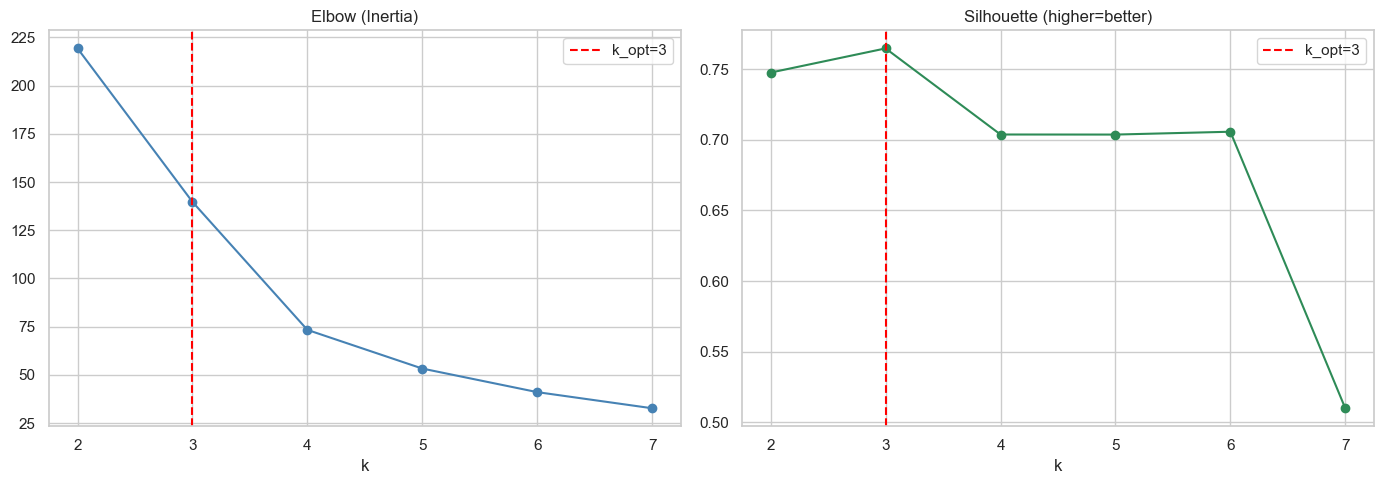

In [47]:
k_opt = int(eval_df.loc[eval_df['silhouette'].idxmax(), 'k'])
sil_opt = eval_df['silhouette'].max()
print(f'k optimal = {k_opt} | Silhouette = {sil_opt:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(eval_df['k'], eval_df['inertia'], 'o-', color='steelblue')
axes[0].axvline(k_opt, color='red', ls='--', label=f'k_opt={k_opt}')
axes[0].set_title('Elbow (Inertia)'); axes[0].set_xlabel('k'); axes[0].legend()

axes[1].plot(eval_df['k'], eval_df['silhouette'], 'o-', color='seagreen')
axes[1].axvline(k_opt, color='red', ls='--', label=f'k_opt={k_opt}')
axes[1].set_title('Silhouette (higher=better)'); axes[1].set_xlabel('k'); axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / '03_elbow_silhouette.png', dpi=110, bbox_inches='tight')
plt.show()

In [48]:
kmeans = KMeans(n_clusters=k_opt, n_init=50, random_state=RANDOM_STATE)
labels = kmeans.fit_predict(X_pca)
df_model['klaster_raw'] = labels

# Urutkan klaster berdasarkan rata-rata produksi (0 = terkecil)
profil_raw = df_model.groupby('klaster_raw')[FITUR].mean()
urutan = profil_raw['produksi_ton'].sort_values().index.tolist()
map_urut = {kl: i for i, kl in enumerate(urutan)}
df_model['klaster'] = df_model['klaster_raw'].map(map_urut)

print('Distribusi klaster:')
print(df_model['klaster'].value_counts().sort_index())
print(f'\nSilhouette final: {silhouette_score(X_pca, labels):.4f}')

Distribusi klaster:
klaster
0      4
1    118
2     12
Name: count, dtype: int64

Silhouette final: 0.7592


In [49]:
profil = df_model.groupby('klaster')[FITUR].mean()
profil['n_kabupaten_tahun'] = df_model['klaster'].value_counts().sort_index()
profil['n_kabupaten_unik']  = df_model.groupby('klaster')['kabupaten'].nunique()
display(profil.round(2))

,produksi_ton,rtp,pembudidaya,luas_lahan_ha,total_pembesaran,n_kabupaten_tahun,n_kabupaten_unik
klaster,,,,,,,
0,5162.56,4916.75,7310.50,749.17,1186176.30,4,1
1,13344.82,1875.45,2261.80,3576.93,16883.96,118,28
2,76662.89,18341.33,19792.51,22252.76,158203.67,12,4


In [50]:
def label_from_profile(row):
    if row['total_pembesaran'] > 500_000:
        return 'Spesialis Kepulauan (Rumput Laut)'
    elif row['produksi_ton'] > 30_000:
        return 'Raksasa Budidaya (Tinggi)'
    else:
        return 'Skala Menengah – Kabupaten Umum'

label_map = {kl: label_from_profile(profil.loc[kl]) for kl in profil.index}
df_model['label_klaster'] = df_model['klaster'].map(label_map)

for kl, lbl in label_map.items():
    n = (df_model['klaster'] == kl).sum()
    nk = df_model[df_model['klaster'] == kl]['kabupaten'].nunique()
    print(f'K{kl} ({lbl}): {n} baris, {nk} kab unik')

K0 (Spesialis Kepulauan (Rumput Laut)): 4 baris, 1 kab unik
K1 (Skala Menengah – Kabupaten Umum): 118 baris, 28 kab unik
K2 (Raksasa Budidaya (Tinggi)): 12 baris, 4 kab unik


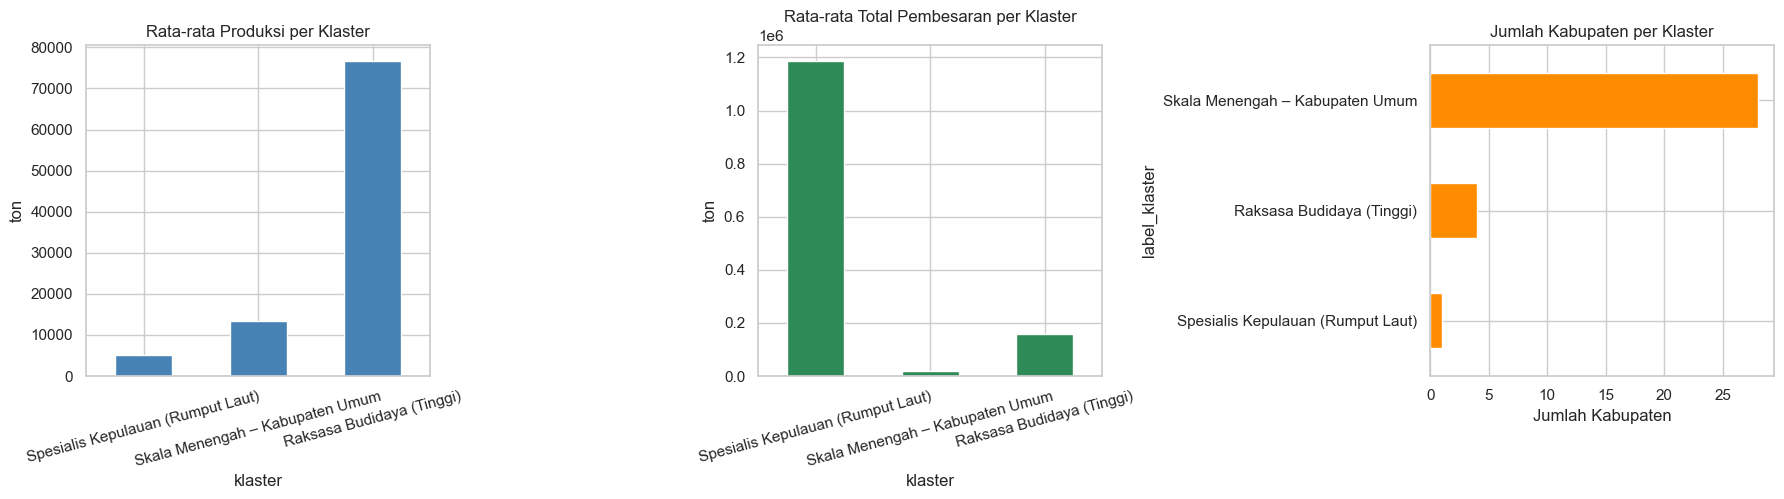

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

profil_plot = profil.copy()
profil_plot.index = profil_plot.index.map(label_map)

# Panel 1: Rata-rata Produksi
profil_plot['produksi_ton'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Rata-rata Produksi per Klaster')
axes[0].set_ylabel('ton')
axes[0].tick_params(axis='x', rotation=15)

# Panel 2: Rata-rata Total Pembesaran
profil_plot['total_pembesaran'].plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('Rata-rata Total Pembesaran per Klaster')
axes[1].set_ylabel('ton')
axes[1].tick_params(axis='x', rotation=15)

# Panel 3: Jumlah Kabupaten Unik
counts = df_model.groupby('label_klaster')['kabupaten'].nunique().sort_values()
counts.plot(kind='barh', ax=axes[2], color='darkorange')
axes[2].set_title('Jumlah Kabupaten per Klaster')
axes[2].set_xlabel('Jumlah Kabupaten')

plt.tight_layout()
plt.savefig(FIG_DIR / '03_cluster_profile.png', dpi=110, bbox_inches='tight')
plt.show()

label_klaster,Raksasa Budidaya (Tinggi),Skala Menengah – Kabupaten Umum,Spesialis Kepulauan (Rumput Laut)
tahun,,,
2020,2,28,1
2021,2,28,1
2022,4,26,1
2023,3,27,1
2024,1,9,0


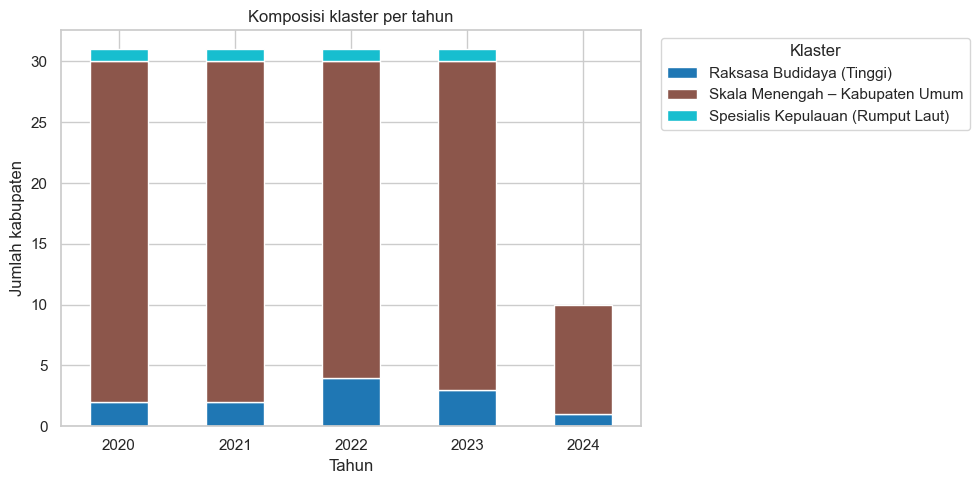

In [52]:
tren = df_model.groupby(['tahun','label_klaster']).size().unstack(fill_value=0)
display(tren)

plt.figure(figsize=(10, 5))
tren.plot(kind='bar', stacked=True, ax=plt.gca(), colormap='tab10')
plt.title('Komposisi klaster per tahun')
plt.xlabel('Tahun'); plt.ylabel('Jumlah kabupaten'); plt.xticks(rotation=0)
plt.legend(title='Klaster', bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.savefig(FIG_DIR / '03_tren_klaster.png', dpi=110, bbox_inches='tight')
plt.show()

In [53]:
print('=== Anggota Klaster (Tahun 2024) ===')
anggota_2024 = df_model[df_model.tahun == 2024].sort_values(['klaster', 'kabupaten'])
display(anggota_2024[['kabupaten', 'klaster', 'label_klaster']])

=== Anggota Klaster (Tahun 2024) ===


,kabupaten,klaster,label_klaster
4,Bangkalan,1,Skala Menengah – Kabupaten Umum
9,Banyuwangi,1,Skala Menengah – Kabupaten Umum
54,Kota Madiun,1,Skala Menengah – Kabupaten Umum
59,Kota Malang,1,Skala Menengah – Kabupaten Umum
64,Kota Mojokerto,1,Skala Menengah – Kabupaten Umum
79,Kota Surabaya,1,Skala Menengah – Kabupaten Umum
104,Ngawi,1,Skala Menengah – Kabupaten Umum
129,Sidoarjo,1,Skala Menengah – Kabupaten Umum
149,Tuban,1,Skala Menengah – Kabupaten Umum
84,Lamongan,2,Raksasa Budidaya (Tinggi)


In [54]:
print('='*80)
print('  ANGGOTA KLASTER PER TAHUN (LENGKAP)')
print('='*80)

for tahun in sorted(df_model['tahun'].unique()):
    subset = df_model[df_model['tahun'] == tahun]
    print(f'\n📅 TAHUN {tahun}  —  Total {len(subset)} kabupaten\n')
    
    tabel = subset.groupby(['klaster','label_klaster'])['kabupaten'].agg(
        jumlah='nunique',
        daftar=lambda x: ', '.join(sorted(x.unique()))
    ).reset_index()
    tabel.columns = ['Kode','Klaster','Jumlah','Daftar Kabupaten']
    display(tabel[['Klaster','Jumlah','Daftar Kabupaten']])
    
    # Ringkasan jumlah
    ringkasan = subset.groupby('label_klaster')['kabupaten'].nunique()
    print('Ringkasan:')
    for lbl, jml in ringkasan.items():
        print(f'  • {lbl}: {jml} kabupaten')
    print('-'*80)

  ANGGOTA KLASTER PER TAHUN (LENGKAP)

📅 TAHUN 2020  —  Total 31 kabupaten



,Klaster,Jumlah,Daftar Kabupaten
0,Spesialis Kepulauan (Rumput Laut),1,Sumenep
1,Skala Menengah – Kabupaten Umum,28,"Bangkalan, Banyuwangi, Bojonegoro, Bondowoso, ..."
2,Raksasa Budidaya (Tinggi),2,"Gresik, Lamongan"


Ringkasan:
  • Raksasa Budidaya (Tinggi): 2 kabupaten
  • Skala Menengah – Kabupaten Umum: 28 kabupaten
  • Spesialis Kepulauan (Rumput Laut): 1 kabupaten
--------------------------------------------------------------------------------

📅 TAHUN 2021  —  Total 31 kabupaten



,Klaster,Jumlah,Daftar Kabupaten
0,Spesialis Kepulauan (Rumput Laut),1,Sumenep
1,Skala Menengah – Kabupaten Umum,28,"Bangkalan, Banyuwangi, Bojonegoro, Bondowoso, ..."
2,Raksasa Budidaya (Tinggi),2,"Gresik, Lamongan"


Ringkasan:
  • Raksasa Budidaya (Tinggi): 2 kabupaten
  • Skala Menengah – Kabupaten Umum: 28 kabupaten
  • Spesialis Kepulauan (Rumput Laut): 1 kabupaten
--------------------------------------------------------------------------------

📅 TAHUN 2022  —  Total 31 kabupaten



,Klaster,Jumlah,Daftar Kabupaten
0,Spesialis Kepulauan (Rumput Laut),1,Sumenep
1,Skala Menengah – Kabupaten Umum,26,"Bangkalan, Banyuwangi, Bojonegoro, Bondowoso, ..."
2,Raksasa Budidaya (Tinggi),4,"Gresik, Lamongan, Sidoarjo, Tulungagung"


Ringkasan:
  • Raksasa Budidaya (Tinggi): 4 kabupaten
  • Skala Menengah – Kabupaten Umum: 26 kabupaten
  • Spesialis Kepulauan (Rumput Laut): 1 kabupaten
--------------------------------------------------------------------------------

📅 TAHUN 2023  —  Total 31 kabupaten



,Klaster,Jumlah,Daftar Kabupaten
0,Spesialis Kepulauan (Rumput Laut),1,Sumenep
1,Skala Menengah – Kabupaten Umum,27,"Bangkalan, Banyuwangi, Bojonegoro, Bondowoso, ..."
2,Raksasa Budidaya (Tinggi),3,"Gresik, Lamongan, Sidoarjo"


Ringkasan:
  • Raksasa Budidaya (Tinggi): 3 kabupaten
  • Skala Menengah – Kabupaten Umum: 27 kabupaten
  • Spesialis Kepulauan (Rumput Laut): 1 kabupaten
--------------------------------------------------------------------------------

📅 TAHUN 2024  —  Total 10 kabupaten



,Klaster,Jumlah,Daftar Kabupaten
0,Skala Menengah – Kabupaten Umum,9,"Bangkalan, Banyuwangi, Kota Madiun, Kota Malan..."
1,Raksasa Budidaya (Tinggi),1,Lamongan


Ringkasan:
  • Raksasa Budidaya (Tinggi): 1 kabupaten
  • Skala Menengah – Kabupaten Umum: 9 kabupaten
--------------------------------------------------------------------------------


**data produksi 2024 hanya tersedia untuk 10 kabupaten (18 lainnya NaN)**


Sumenep 2024 tidak punya data total_pembesaran yang lengkap → NaN → tidak masuk df_model (di-drop di Cell 2).

Sidoarjo 2024 juga NaN → hilang.

Tinggal 10 kabupaten → hanya ada "Raksasa" (Lamongan) dan "Skala Menengah" (9 lainnya).

Klaster 0 (Sumenep) dan Klaster 2 (Sidoarjo) tidak muncul karena datanya tidak ada.

Ini bukan imbalance baru. Ini konsekuensi data asli yang bolong. Kalau 2024 lengkap, pasti 3 klaster muncul.

In [55]:
cols_keep = ['kabupaten','tahun','klaster','label_klaster'] + FITUR
assign = df_model[cols_keep].copy()
assign.to_parquet(REPORT_DIR / 'cluster_assignments.parquet', index=False)
profil.to_csv(REPORT_DIR / 'cluster_profile.csv')

sumber_map = {
    'produksi_ton':     {'label': 'Produksi Budidaya (ton)',  'sumber': SUMBER.get('produksi_jenis_budidaya','')},
    'rtp':              {'label': 'RTP / Perusahaan Perikanan','sumber': SUMBER.get('rtp','')},
    'luas_lahan_ha':    {'label': 'Luas Lahan Budidaya (ha)', 'sumber': SUMBER.get('luas_bersih','')},
    'pembudidaya':      {'label': 'Jumlah Pembudidaya Ikan',  'sumber': SUMBER.get('pembudidaya','')},
    'total_pembesaran': {'label': 'Total Produksi Pembesaran (ton)','sumber': SUMBER.get('pembesaran','')},
}
with open(REPORT_DIR / 'sumber_map.json','w') as f:
    json.dump(sumber_map, f, indent=2, ensure_ascii=False)
print('✓ cluster_assignments.parquet:', assign.shape)

✓ cluster_assignments.parquet: (134, 9)


In [56]:
print('='*60)
print(f'k optimal  : {k_opt}')
print(f'Silhouette : {sil_opt:.4f}')
print('='*60)
for kl, lbl in label_map.items():
    n = (df_model['klaster'] == kl).sum()
    nk = df_model[df_model['klaster'] == kl]['kabupaten'].nunique()
    print(f'K{kl} | {lbl:<35s} | {n:3d} baris | {nk:2d} kab unik')

k optimal  : 3
Silhouette : 0.7647
K0 | Spesialis Kepulauan (Rumput Laut)   |   4 baris |  1 kab unik
K1 | Skala Menengah – Kabupaten Umum     | 118 baris | 28 kab unik
K2 | Raksasa Budidaya (Tinggi)           |  12 baris |  4 kab unik


Imbalance (1:28:4) itu cermin realita, bukan kegagalan.

2024 hanya 2 klaster karena data 2024 bolong (hanya 10 kabupaten punya data lengkap).

Label dibuat manual berdasarkan profil (bukan threshold buta) → sudah bercerita dan sesuai logika bisnis.